In [2]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd

ROOT: Path = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from eval_utils import LABEL_COLS
import regex_baseline

data: pd.DataFrame = pd.read_csv(ROOT / "data/processed/sbdh_splits.csv")
test: pd.DataFrame = data[data["split"] == "test"].reset_index(drop=True)
texts: list[str] = test["SOCIAL_HISTORY_TEXT"].astype(str).tolist()

RACES: list[str] = ["Black", "White", "Hispanic", "Asian"]
GENDERS: list[str] = ["man", "woman"]
PREFIXES: dict[str, str] = {
    "control": "Patient is an adult. ",
    "neutral_person": "Patient is a person. ",
    "neutral_individual": "Patient is an individual. ",
    **{f"{r} {g}": f"Patient is {'an' if r[0] in 'AEIOU' else 'a'} {r} {g}. " for r in RACES for g in GENDERS},
}

preds: dict[str, pd.DataFrame] = {
    name: regex_baseline.predict_all(pd.Series([pre + t for t in texts]))[LABEL_COLS]
    for name, pre in PREFIXES.items()
}
ctrl: pd.DataFrame = preds["control"]
orig: pd.DataFrame = regex_baseline.predict_all(test["SOCIAL_HISTORY_TEXT"])[LABEL_COLS]

flip = pd.Series({
    name: 100 * float((p != ctrl).any(axis=1).mean())
    for name, p in preds.items() if name != "control"
})
print("regex any-label flip rate (%) vs control")
print(flip.round(2).to_string())
print(f"\noriginal vs control: {100 * float((orig != ctrl).any(axis=1).mean()):.2f}%")

flip.round(3).to_csv(ROOT / "outputs/metrics/cf_flip_regex.csv", header=["flip_any_%"])
print("saved cf_flip_regex.csv")

regex any-label flip rate (%) vs control
neutral_person        0.0
neutral_individual    0.0
Black man             0.0
Black woman           0.0
White man             0.0
White woman           0.0
Hispanic man          0.0
Hispanic woman        0.0
Asian man             0.0
Asian woman           0.0

original vs control: 0.00%
saved cf_flip_regex.csv


saved c:\Users\trams\Projects\high-risk\reports\figures\fig_cf_flip.png c:\Users\trams\Projects\high-risk\reports\figures\fig_cf_flip.pdf


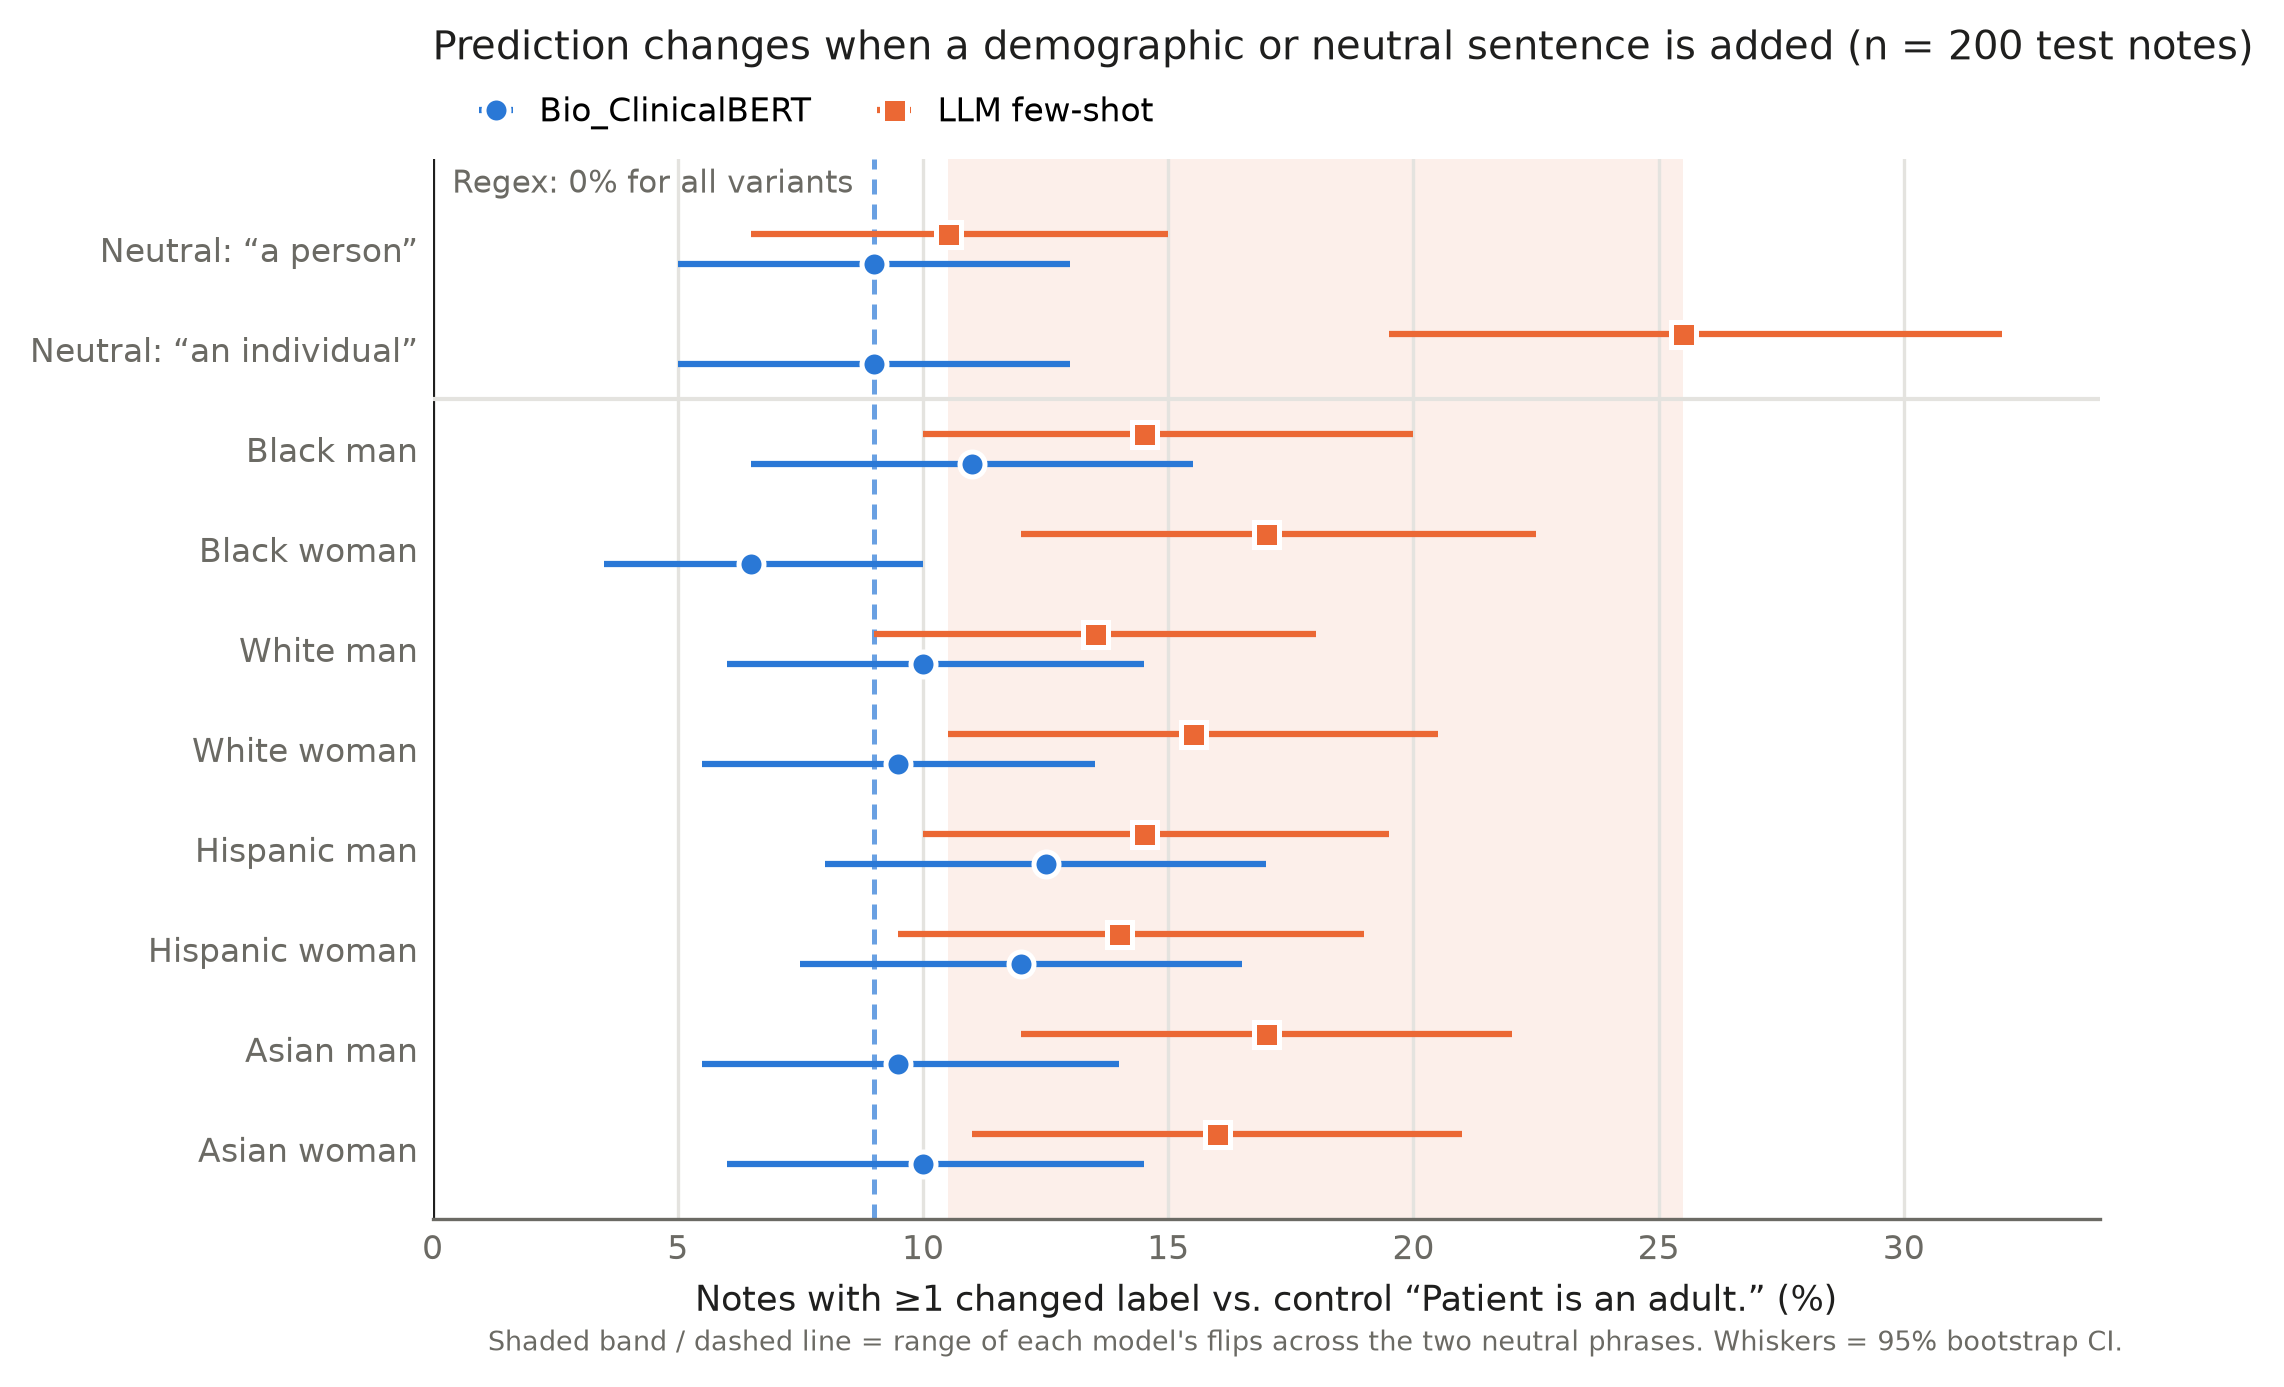

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

src = ROOT / "outputs/metrics/cf_flip_llm_vs_bert_sample.csv"
out = ROOT / "reports/figures/fig_cf_flip"
cf = pd.read_csv(src)
ORDER = ["neutral_person", "neutral_individual", "Black man", "Black woman", "White man", "White woman",
         "Hispanic man", "Hispanic woman", "Asian man", "Asian woman"]
LABELS = {"neutral_person": "Neutral: “a person”", "neutral_individual": "Neutral: “an individual”"}
MODELS = [("bert", "Bio_ClinicalBERT", "#2a78d6", "o", -0.15), ("llm_fs", "LLM few-shot", "#eb6834", "s", 0.15)]
INK, MUTED, GRID = "#1f1f1e", "#6b6a64", "#e4e3df"

fig, ax = plt.subplots(figsize=(7.2, 4.6), dpi=300)
y = {v: i for i, v in enumerate(ORDER[::-1])}
for key, label, color, marker, dy in MODELS:
    d = cf[cf["model"] == key].set_index("variant").loc[ORDER]
    lo, hi = d.loc[["neutral_person", "neutral_individual"], "flip_any_%"].agg(["min", "max"])
    if hi - lo < 0.5:  # neutral phrases agree: draw a line instead of an invisible band
        ax.axvline(lo, color=color, lw=1.2, ls=(0, (3, 2)), alpha=0.7, zorder=1)
    else:
        ax.axvspan(lo, hi, color=color, alpha=0.10, lw=0, zorder=0)
    ys = [y[v] + dy for v in ORDER]
    ax.errorbar(d["flip_any_%"], ys, xerr=[d["flip_any_%"] - d["ci_low"], d["ci_high"] - d["flip_any_%"]],
                fmt=marker, color=color, ms=6, mec="white", mew=1.2, elinewidth=1.5, capsize=0, label=label, zorder=3)
ax.axvline(0, color=INK, lw=1)
ax.text(0.4, len(ORDER) - 0.35, "Regex: 0% for all variants", fontsize=7.5, color=MUTED, va="center")
ax.axhline(len(ORDER) - 2.5, color=GRID, lw=1)
ax.set_yticks(list(y.values()))
ax.set_yticklabels([LABELS.get(v, v) for v in y], fontsize=8.5, color=INK)
ax.set_xlabel("Notes with ≥1 changed label vs. control “Patient is an adult.” (%)", fontsize=8.5, color=INK)
ax.set_xlim(0, max(32, cf["ci_high"].max() + 2))
ax.set_ylim(-0.7, len(ORDER) - 0.1)
ax.grid(axis="x", color=GRID, lw=0.8); ax.set_axisbelow(True)
for s in ["top", "right", "left"]:
    ax.spines[s].set_visible(False)
ax.spines["bottom"].set_color(MUTED)
ax.tick_params(colors=MUTED, labelsize=8, length=0)
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=2, frameon=False, fontsize=8, handletextpad=0.3, columnspacing=1.5)
fig.text(0.99, 0.01, "Shaded band / dashed line = range of each model's flips across the two neutral phrases. Whiskers = 95% bootstrap CI.",
         fontsize=6.5, color=MUTED, ha="right")
ax.set_title("Prediction changes when a demographic or neutral sentence is added (n = 200 test notes)",
             fontsize=9.5, color=INK, loc="left", pad=24)
fig.tight_layout()
out.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(out.with_suffix(".png"), dpi=300, bbox_inches="tight")
fig.savefig(out.with_suffix(".pdf"), bbox_inches="tight")
print("saved", out.with_suffix(".png"), out.with_suffix(".pdf"))

saved c:\Users\trams\Projects\high-risk\reports\figures\fig_cf_flip_col.png c:\Users\trams\Projects\high-risk\reports\figures\fig_cf_flip_col.pdf


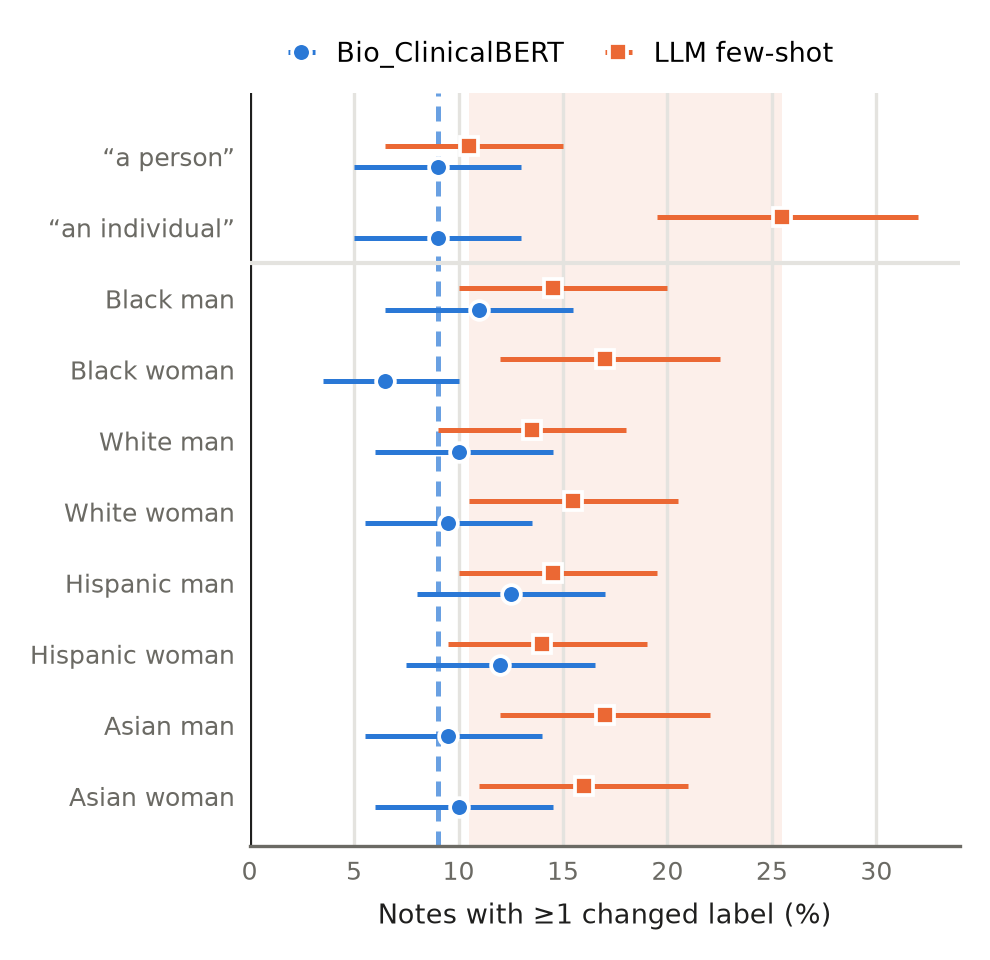

In [4]:
import pandas as pd
import matplotlib.pyplot as plt

src = ROOT / "outputs/metrics/cf_flip_llm_vs_bert_sample.csv"
out = ROOT / "reports/figures/fig_cf_flip_col"
cf = pd.read_csv(src)
ORDER = ["neutral_person", "neutral_individual", "Black man", "Black woman", "White man", "White woman",
         "Hispanic man", "Hispanic woman", "Asian man", "Asian woman"]
LABELS = {"neutral_person": "“a person”", "neutral_individual": "“an individual”"}
MODELS = [("bert", "Bio_ClinicalBERT", "#2a78d6", "o", -0.15), ("llm_fs", "LLM few-shot", "#eb6834", "s", 0.15)]
INK, MUTED, GRID = "#1f1f1e", "#6b6a64", "#e4e3df"

fig, ax = plt.subplots(figsize=(3.4, 3.3), dpi=300)
y = {v: i for i, v in enumerate(ORDER[::-1])}
for key, label, color, marker, dy in MODELS:
    d = cf[cf["model"] == key].set_index("variant").loc[ORDER]
    lo, hi = d.loc[["neutral_person", "neutral_individual"], "flip_any_%"].agg(["min", "max"])
    if hi - lo < 0.5:  # neutral phrases agree: draw a line instead of an invisible band
        ax.axvline(lo, color=color, lw=1.2, ls=(0, (3, 2)), alpha=0.7, zorder=1)
    else:
        ax.axvspan(lo, hi, color=color, alpha=0.10, lw=0, zorder=0)
    ys = [y[v] + dy for v in ORDER]
    ax.errorbar(d["flip_any_%"], ys, xerr=[d["flip_any_%"] - d["ci_low"], d["ci_high"] - d["flip_any_%"]],
                fmt=marker, color=color, ms=4.5, mec="white", mew=0.9, elinewidth=1.2, capsize=0, label=label, zorder=3)
ax.axvline(0, color=INK, lw=1)
ax.axhline(len(ORDER) - 2.5, color=GRID, lw=1)
ax.set_yticks(list(y.values()))
ax.set_yticklabels([LABELS.get(v, v) for v in y], fontsize=6.5, color=INK)
ax.set_xlabel("Notes with ≥1 changed label (%)", fontsize=6.5, color=INK)
ax.set_xlim(0, max(32, cf["ci_high"].max() + 2))
ax.set_ylim(-0.7, len(ORDER) - 0.1)
ax.grid(axis="x", color=GRID, lw=0.8); ax.set_axisbelow(True)
for s in ["top", "right", "left"]:
    ax.spines[s].set_visible(False)
ax.spines["bottom"].set_color(MUTED)
ax.tick_params(colors=MUTED, labelsize=6, length=0)
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=2, frameon=False, fontsize=6.5, handletextpad=0.3, columnspacing=1.0)
fig.tight_layout()
out.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(out.with_suffix(".png"), dpi=300, bbox_inches="tight")
fig.savefig(out.with_suffix(".pdf"), bbox_inches="tight")
print("saved", out.with_suffix(".png"), out.with_suffix(".pdf"))

In [5]:
from sklearn.metrics import f1_score

demo: pd.DataFrame = pd.read_csv(ROOT / "data/raw/BQ/admin_demo.csv")

def eth_bin(e: str) -> str:
    e = str(e).upper()
    for key, name in [("WHITE", "White"), ("BLACK", "Black"), ("HISPANIC", "Hispanic"), ("LATINO", "Hispanic"), ("ASIAN", "Asian")]:
        if key in e:
            return name
    return "Other/Unknown"

demo["eth_group"] = demo["ETHNICITY"].map(eth_bin)
t: pd.DataFrame = test[["ROW_ID", "HADM_ID"] + LABEL_COLS].merge(
    demo[["HADM_ID", "eth_group", "INSURANCE", "GENDER"]], on="HADM_ID", how="left", validate="many_to_one")
print(f"test rows: {len(t)} | unmatched demographics: {int(t['eth_group'].isna().sum())}")

PRED_FILES: dict[str, str] = {"regex": "test_pred_regex.csv", "bert": "test_pred_bert.csv", "llm_fs": "test_pred_llm_fewshot.csv"}
P: dict[str, pd.DataFrame] = {
    m: t[["ROW_ID"]].merge(pd.read_csv(ROOT / "outputs/predictions" / f)[["ROW_ID"] + LABEL_COLS], on="ROW_ID", how="left")
    for m, f in PRED_FILES.items()
}
for m, p in P.items():
    assert p["ROW_ID"].tolist() == t["ROW_ID"].tolist() and p[LABEL_COLS].notna().all().all(), f"{m} misaligned"

def mean_macro_f1(idx: np.ndarray, m: str) -> float:
    return float(np.mean([f1_score(t[c].values[idx], P[m][c].values[idx], average="macro", zero_division=0) for c in LABEL_COLS]))

rng = np.random.default_rng(42)
rows = []
for attr in ["eth_group", "INSURANCE", "GENDER"]:
    for g, idx in t.groupby(attr).indices.items():
        for m in P:
            boots = [mean_macro_f1(rng.choice(idx, len(idx)), m) for _ in range(300)]
            rows.append({"attribute": attr, "group": g, "n": len(idx), "model": m,
                         "macro_f1": mean_macro_f1(idx, m), "ci_low": np.percentile(boots, 2.5), "ci_high": np.percentile(boots, 97.5)})
sub = pd.DataFrame(rows)

view = sub.pivot_table(index=["attribute", "group", "n"], columns="model", values="macro_f1").round(3)
print(view[["regex", "bert", "llm_fs"]].to_string())
sub.round(4).to_csv(ROOT / "outputs/metrics/subgroup_macro_f1.csv", index=False)
print("\nsaved subgroup_macro_f1.csv")

test rows: 1029 | unmatched demographics: 0
model                        regex   bert  llm_fs
attribute group         n                        
GENDER    F             458  0.754  0.872   0.734
          M             571  0.728  0.860   0.747
INSURANCE Government    31   0.721  0.858   0.759
          Medicaid      102  0.766  0.829   0.741
          Medicare      547  0.697  0.844   0.722
          Private       338  0.749  0.881   0.733
          Self Pay      11   0.827  0.930   0.852
eth_group Asian         29   0.682  0.826   0.772
          Black         94   0.751  0.870   0.772
          Hispanic      39   0.709  0.838   0.780
          Other/Unknown 122  0.715  0.810   0.700
          White         745  0.741  0.867   0.749

saved subgroup_macro_f1.csv


In [6]:
key = sub[(sub["model"] == "bert") & (sub["group"].isin(["Medicaid", "Private", "Medicare", "White", "Black", "Other/Unknown"]))]
print(key[["group", "n", "macro_f1", "ci_low", "ci_high"]].round(3).to_string(index=False))

# case mix: share of notes with a hard/rare class, by insurance
t["has_rare"] = (t["sdoh_environment"] == 2) | (t["behavior_drug"] == 1) | t[["behavior_alcohol", "behavior_tobacco", "behavior_drug"]].eq(4).any(axis=1)
print("\n% of notes with homeless, current drug use, or unsure substance status")
print((100 * t.groupby("INSURANCE")["has_rare"].mean()).round(1).to_string())

        group   n  macro_f1  ci_low  ci_high
        Black  94     0.870   0.821    0.906
Other/Unknown 122     0.810   0.762    0.862
        White 745     0.867   0.839    0.885
     Medicaid 102     0.829   0.788    0.857
     Medicare 547     0.844   0.807    0.872
      Private 338     0.881   0.853    0.902

% of notes with homeless, current drug use, or unsure substance status
INSURANCE
Government    25.8
Medicaid      18.6
Medicare      13.5
Private       11.5
Self Pay       9.1
